In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, random_split
from torchvision import models
from torchsummary import summary
import os
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [2]:
# =======================
# STEP 0: Initialize
# =======================
EPOCHS = 10
BATCH_SIZE = 16
LEARNING_RATE = 0.001

In [3]:
# =======================
# STEP 1: Data Preparation
# =======================

# Transforms for training and validation
data_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

# Load the full dataset from the root directory
data_dir = "/content/flower_photos"
full_dataset = datasets.ImageFolder(root=data_dir, transform=data_transforms)

# Split into 80% training and 20% validation sets
train_size = int(0.8 * len(full_dataset))
val_size = len(full_dataset) - train_size
train_dataset, val_dataset = random_split(full_dataset, [train_size, val_size])

# Create PyTorch DataLoaders
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

# Verify classes and batch shape
print("Classes:", full_dataset.classes)
images, labels = next(iter(train_loader))
print("Batch shape:", images.shape, "Labels shape:", labels.shape)

Classes: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']
Batch shape: torch.Size([16, 3, 224, 224]) Labels shape: torch.Size([16])


In [4]:
# ===========================
# STEP 2: Load Pretrained Model
# ===========================
from torchvision.models import ResNet50_Weights

model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
model.fc = nn.Linear(model.fc.in_features, 5)  # for 5-class classification

# Freeze all but final layer
for param in model.parameters():
    param.requires_grad = False
for param in model.fc.parameters():
    param.requires_grad = True

# Move model to device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)


Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 182MB/s]


In [5]:
# ===================
# STEP 3: Loss & Optimizer
# ===================

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

In [6]:
all_preds = []
all_labels = []

def train_model(model, criterion, optimizer, train_loader, val_loader, epochs=10):

    for epoch in range(epochs):
        model.train()
        train_correct = 0
        train_total = 0
        running_loss = 0.0

        print(f"\nEpoch {epoch + 1}/{epochs}")
        print("-" * 30)

        for i, (images, labels) in enumerate(train_loader):
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()
            _, preds = torch.max(outputs, 1)
            batch_correct = (preds == labels).sum().item()
            train_correct += batch_correct
            train_total += labels.size(0)

        train_acc = train_correct / train_total
        print(f"Epoch {epoch+1} Summary - Loss: {running_loss:.4f}, Train Accuracy: {train_acc:.4f}")

        # Validation
        model.eval()
        val_correct = 0
        val_total = 0
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                _, preds = torch.max(outputs, 1)

                all_preds.extend(preds.cpu().numpy())
                all_labels.extend(labels.cpu().numpy())

                val_correct += (preds == labels).sum().item()
                val_total += labels.size(0)

        val_acc = val_correct / val_total
        print(f"Validation Accuracy: {val_acc:.4f}")


In [7]:
# ===================
# Train the model
# ===================
train_model(model, criterion, optimizer, train_loader, val_loader, epochs=EPOCHS)


Epoch 1/10
------------------------------
Epoch 1 Summary - Loss: 138.0110, Train Accuracy: 0.7796
Validation Accuracy: 0.9114

Epoch 2/10
------------------------------
Epoch 2 Summary - Loss: 72.5865, Train Accuracy: 0.8859
Validation Accuracy: 0.9169

Epoch 3/10
------------------------------
Epoch 3 Summary - Loss: 57.0561, Train Accuracy: 0.9125
Validation Accuracy: 0.9264

Epoch 4/10
------------------------------
Epoch 4 Summary - Loss: 47.5550, Train Accuracy: 0.9237
Validation Accuracy: 0.9292

Epoch 5/10
------------------------------
Epoch 5 Summary - Loss: 41.4269, Train Accuracy: 0.9407
Validation Accuracy: 0.9278

Epoch 6/10
------------------------------
Epoch 6 Summary - Loss: 34.7778, Train Accuracy: 0.9496
Validation Accuracy: 0.9319

Epoch 7/10
------------------------------
Epoch 7 Summary - Loss: 33.0671, Train Accuracy: 0.9516
Validation Accuracy: 0.9319

Epoch 8/10
------------------------------
Epoch 8 Summary - Loss: 30.4546, Train Accuracy: 0.9564
Validation 

**Confusion Matrix**

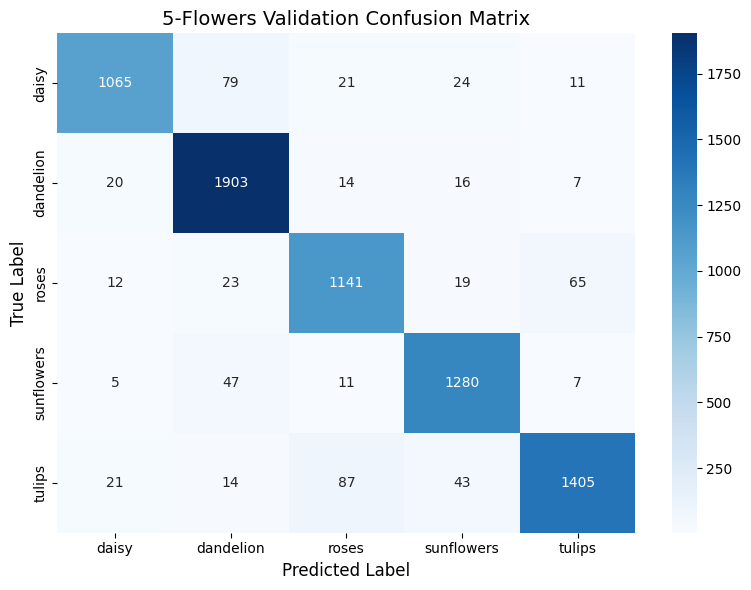

In [8]:
# Get class names (works whether val_dataset is a Subset or ImageFolder)
class_names = (
    val_dataset.dataset.classes
    if hasattr(val_dataset, "dataset")
    else full_dataset.classes
)

# Compute and plot the Confusion Matrix
cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted Label", fontsize=12)
plt.ylabel("True Label", fontsize=12)
plt.title("5-Flowers Validation Confusion Matrix", fontsize=14)
plt.tight_layout()
plt.show()

In [9]:
!pip install -q onnx onnxscript onnxruntime-gpu

In [ ]:
# ==========================================
# Save & Reload the PyTorch Model
# ==========================================
import os, time
import numpy as np
import torch
import torch.nn as nn
from torchvision import models
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

os.makedirs("models", exist_ok=True)
PT_PATH = "models/resnet50_flowers.pth"
ONNX_PATH = "models/resnet50_flowers.onnx"
class_names = full_dataset.classes
NUM_CLASSES = len(class_names)

model.eval()
torch.save(model.state_dict(), PT_PATH)
print(f"Saved PyTorch weights -> {PT_PATH} ({os.path.getsize(PT_PATH)/1e6:.1f} MB)")

# Reload into a fresh model to prove the saved file works on its own
pt_model = models.resnet50(weights=None)
pt_model.fc = nn.Linear(pt_model.fc.in_features, NUM_CLASSES)
pt_model.load_state_dict(torch.load(PT_PATH, map_location=device))
pt_model = pt_model.to(device).eval()
print("Reloaded PyTorch model OK")

Saved PyTorch weights -> models/resnet50_flowers.pth (94.4 MB)
Reloaded PyTorch model OK


In [ ]:
# ==========================================
# PyTorch Testing (final model only)
# ==========================================
def evaluate_pytorch(net, loader):
    preds, labels, logits_all = [], [], []
    with torch.no_grad():
        for x, y in loader:
            out = net(x.to(device))
            logits_all.append(out.cpu().numpy())
            preds.extend(out.argmax(1).cpu().numpy())
            labels.extend(y.numpy())
    return np.array(preds), np.array(labels), np.concatenate(logits_all)

pt_preds, y_true, pt_logits = evaluate_pytorch(pt_model, val_loader)
pt_acc = accuracy_score(y_true, pt_preds)
print(f"PyTorch validation accuracy: {pt_acc:.4f}\n")
print(classification_report(y_true, pt_preds, target_names=class_names, digits=4))

PyTorch validation accuracy: 0.9251

              precision    recall  f1-score   support

       daisy     0.9224    0.8917    0.9068       120
   dandelion     0.9320    0.9796    0.9552       196
       roses     0.8898    0.8968    0.8933       126
  sunflowers     0.9286    0.9630    0.9455       135
      tulips     0.9448    0.8726    0.9073       157

    accuracy                         0.9251       734
   macro avg     0.9235    0.9207    0.9216       734
weighted avg     0.9253    0.9251    0.9246       734



In [ ]:
# ==========================================
# Export to ONNX
# ==========================================
import onnx

export_model = pt_model.to("cpu").eval()           # export on CPU for portability
dummy_input = torch.randn(1, 3, 224, 224)

torch.onnx.export(
    export_model,
    (dummy_input,),
    ONNX_PATH,
    input_names=["input"],
    output_names=["logits"],
    dynamic_shapes={"x": {0: torch.export.Dim("batch")}},  # any batch size
    dynamo=True,
    external_data=False,                               # keep everything in one .onnx file
)
pt_model = pt_model.to(device)                         # move back for later cells

onnx_model = onnx.load(ONNX_PATH)
onnx.checker.check_model(onnx_model)
print(f"Exported ONNX -> {ONNX_PATH} ({os.path.getsize(ONNX_PATH)/1e6:.1f} MB)")
print("ONNX checker: OK | opset:", onnx_model.opset_import[0].version)
print("Inputs :", [(i.name, [d.dim_param or d.dim_value for d in i.type.tensor_type.shape.dim]) for i in onnx_model.graph.input])
print("Outputs:", [(o.name, [d.dim_param or d.dim_value for d in o.type.tensor_type.shape.dim]) for o in onnx_model.graph.output])

[torch.onnx] Obtain model graph for `ResNet([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `ResNet([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...
[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
Exported ONNX -> models/resnet50_flowers.onnx (94.2 MB)
ONNX checker: OK | opset: 20
Inputs : [('input', ['batch', 3, 224, 224])]
Outputs: [('logits', ['batch', 5])]


In [ ]:
# ==========================================
# ONNX Runtime Session
# ==========================================
import onnxruntime as ort

available = ort.get_available_providers()
providers = [p for p in ["CUDAExecutionProvider", "CPUExecutionProvider"] if p in available]
ort_session = ort.InferenceSession(ONNX_PATH, providers=providers)
print("ONNX Runtime", ort.__version__, "| using:", ort_session.get_providers())

INPUT_NAME = ort_session.get_inputs()[0].name

def onnx_predict(x_np):
    return ort_session.run(None, {INPUT_NAME: x_np.astype(np.float32)})[0]

ONNX Runtime 1.32.0 | using: ['CUDAExecutionProvider', 'CPUExecutionProvider']


In [ ]:
# ==========================================
# Numerical Check - PyTorch vs ONNX
# ==========================================
x, _ = next(iter(val_loader))
with torch.no_grad():
    torch_out = pt_model(x.to(device)).cpu().numpy()
onnx_out = onnx_predict(x.numpy())

max_diff = np.abs(torch_out - onnx_out).max()
print(f"Max abs difference (logits): {max_diff:.2e}")
np.testing.assert_allclose(torch_out, onnx_out, rtol=1e-3, atol=1e-4)
print("PyTorch and ONNX outputs match within tolerance")

Max abs difference (logits): 2.61e-05
PyTorch and ONNX outputs match within tolerance


In [ ]:
# ==========================================
# ONNX Testing on the full validation set
# ==========================================
onnx_preds = []
for x, _ in val_loader:
    onnx_preds.extend(onnx_predict(x.numpy()).argmax(1))
onnx_preds = np.array(onnx_preds)

onnx_acc = accuracy_score(y_true, onnx_preds)
agreement = (onnx_preds == pt_preds).mean()
print(f"ONNX validation accuracy   : {onnx_acc:.4f}")
print(f"PyTorch validation accuracy: {pt_acc:.4f}")
print(f"Prediction agreement       : {agreement*100:.2f}% "
      f"({(onnx_preds != pt_preds).sum()} of {len(y_true)} differ)")

ONNX validation accuracy   : 0.9251
PyTorch validation accuracy: 0.9251
Prediction agreement       : 100.00% (0 of 734 differ)


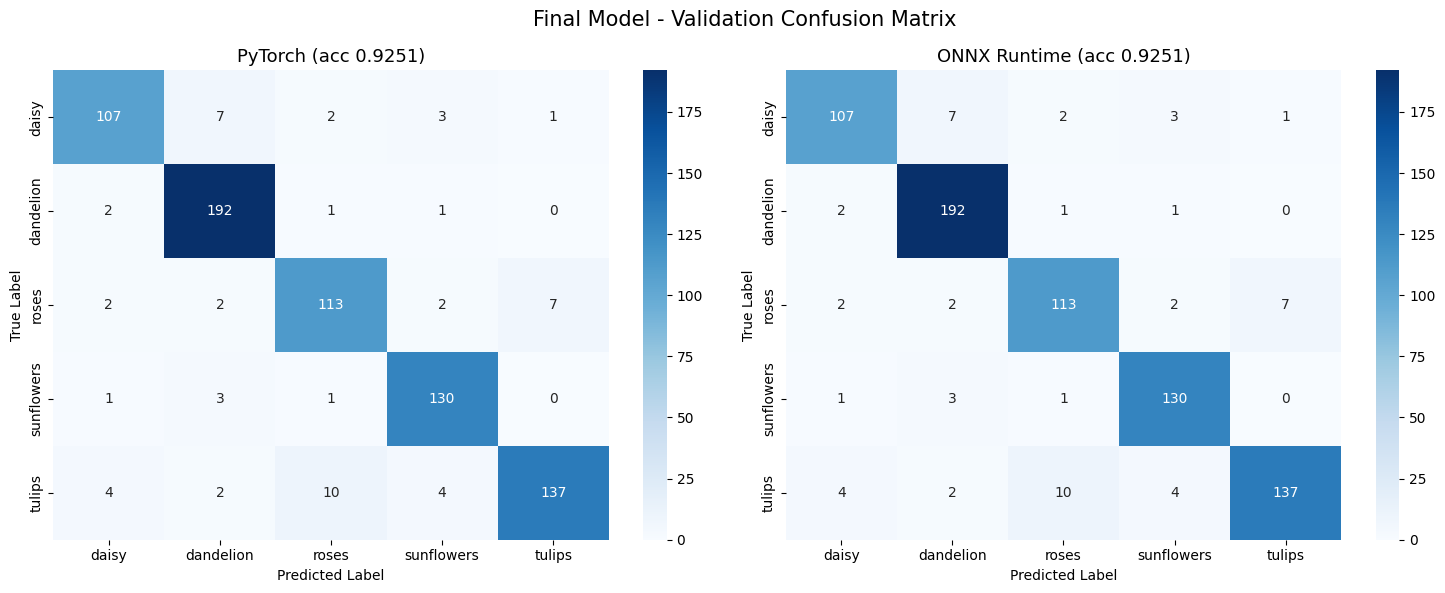

In [ ]:
# ==========================================
# Final Confusion Matrices (PyTorch vs ONNX)
# ==========================================
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, preds, title in [(axes[0], pt_preds, f"PyTorch (acc {pt_acc:.4f})"),
                         (axes[1], onnx_preds, f"ONNX Runtime (acc {onnx_acc:.4f})")]:
    sns.heatmap(confusion_matrix(y_true, preds), annot=True, fmt="d", cmap="Blues",
                xticklabels=class_names, yticklabels=class_names, ax=ax)
    ax.set_title(title, fontsize=13)
    ax.set_xlabel("Predicted Label"); ax.set_ylabel("True Label")
plt.suptitle("Final Model - Validation Confusion Matrix", fontsize=15)
plt.tight_layout()
plt.savefig("models/confusion_matrix_final.png", dpi=120)
plt.show()

In [ ]:
# ==========================================
# Inference Speed Benchmark
# ==========================================
def benchmark(fn, x, warmup=10, runs=50):
    for _ in range(warmup):
        fn(x)
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    t0 = time.perf_counter()
    for _ in range(runs):
        fn(x)
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    return (time.perf_counter() - t0) / runs * 1000  # ms per call

def torch_run(x):
    with torch.no_grad():
        return pt_model(x.to(device)).cpu()

results = []
for bs in [1, 16]:
    x = torch.randn(bs, 3, 224, 224)
    t_pt = benchmark(torch_run, x)
    t_ox = benchmark(onnx_predict, x.numpy())
    results.append((bs, t_pt, t_ox))

print(f"Device: PyTorch={device} | ONNX={ort_session.get_providers()[0]}\n")
print(f"{'Batch':>5} | {'PyTorch ms':>10} | {'ONNX ms':>8} | {'Speed-up':>8} | {'ONNX img/s':>10}")
print("-" * 55)
for bs, t_pt, t_ox in results:
    print(f"{bs:>5} | {t_pt:>10.2f} | {t_ox:>8.2f} | {t_pt/t_ox:>7.2f}x | {bs*1000/t_ox:>10.1f}")

Device: PyTorch=cuda | ONNX=CUDAExecutionProvider

Batch | PyTorch ms |  ONNX ms | Speed-up | ONNX img/s
-------------------------------------------------------
    1 |      21.32 |     5.95 |    3.58x |      168.0
   16 |      50.93 |    53.41 |    0.95x |      299.6


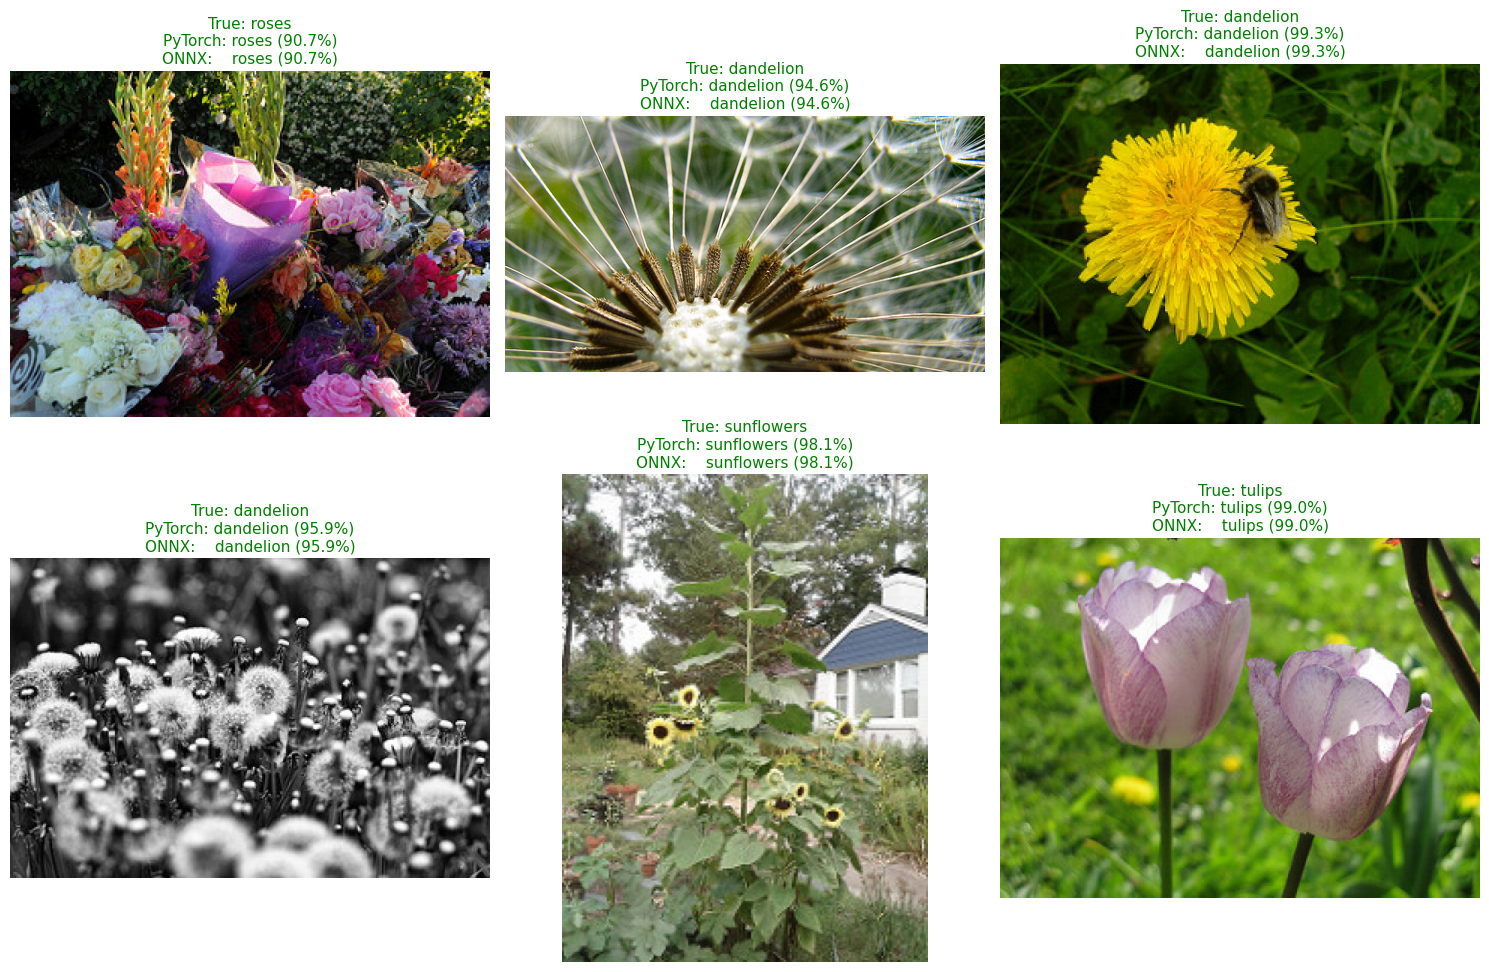

Image: 10894627425_ec76bbc757_n.jpg | True: roses
  roses       PyTorch  90.70% | ONNX  90.70%
  tulips      PyTorch   8.00% | ONNX   8.00%
  daisy       PyTorch   0.79% | ONNX   0.79%


In [ ]:
# ==========================================
# Single-Image Test (PyTorch vs ONNX)
# ==========================================
from PIL import Image
import random

def predict_image(img_path):
    img = Image.open(img_path).convert("RGB")
    x = data_transforms(img).unsqueeze(0)              # same preprocessing as training

    with torch.no_grad():
        pt_prob = torch.softmax(pt_model(x.to(device)), 1).cpu().numpy()[0]
    ox_logits = onnx_predict(x.numpy())[0]
    ox_prob = np.exp(ox_logits - ox_logits.max()); ox_prob /= ox_prob.sum()
    return img, pt_prob, ox_prob

# Pick random validation images (val_dataset is a Subset of full_dataset)
sample_idx = random.sample(list(val_dataset.indices), 6)

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for ax, idx in zip(axes.flat, sample_idx):
    path, true_label = full_dataset.samples[idx]
    img, pt_prob, ox_prob = predict_image(path)
    pt_cls, ox_cls = pt_prob.argmax(), ox_prob.argmax()
    ax.imshow(img); ax.axis("off")
    ax.set_title(f"True: {class_names[true_label]}\n"
                 f"PyTorch: {class_names[pt_cls]} ({pt_prob[pt_cls]*100:.1f}%)\n"
                 f"ONNX:    {class_names[ox_cls]} ({ox_prob[ox_cls]*100:.1f}%)",
                 color="green" if pt_cls == true_label else "red", fontsize=11)
plt.tight_layout()
plt.show()

# Top-3 for one image
path, true_label = full_dataset.samples[sample_idx[0]]
_, pt_prob, ox_prob = predict_image(path)
print(f"Image: {os.path.basename(path)} | True: {class_names[true_label]}")
for i in pt_prob.argsort()[::-1][:3]:
    print(f"  {class_names[i]:<11} PyTorch {pt_prob[i]*100:6.2f}% | ONNX {ox_prob[i]*100:6.2f}%")

In [ ]:
# ==========================================
# Summary
# ==========================================
print("=" * 50)
print("               FINAL SUMMARY")
print("=" * 50)
print(f"PyTorch model : {PT_PATH} ({os.path.getsize(PT_PATH)/1e6:.1f} MB)")
print(f"ONNX model    : {ONNX_PATH} ({os.path.getsize(ONNX_PATH)/1e6:.1f} MB)")
print(f"PyTorch acc   : {pt_acc:.4f}")
print(f"ONNX acc      : {onnx_acc:.4f}")
print(f"Agreement     : {agreement*100:.2f}%")
print(f"Max logit diff: {max_diff:.2e}")
for bs, t_pt, t_ox in results:
    print(f"Batch {bs:>2}      : PyTorch {t_pt:.2f} ms | ONNX {t_ox:.2f} ms ({t_pt/t_ox:.2f}x)")

               FINAL SUMMARY
PyTorch model : models/resnet50_flowers.pth (94.4 MB)
ONNX model    : models/resnet50_flowers.onnx (94.2 MB)
PyTorch acc   : 0.9251
ONNX acc      : 0.9251
Agreement     : 100.00%
Max logit diff: 2.61e-05
Batch  1      : PyTorch 21.32 ms | ONNX 5.95 ms (3.58x)
Batch 16      : PyTorch 50.93 ms | ONNX 53.41 ms (0.95x)
